# Importing Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import Image, display
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from google.colab import files

# Mounting Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Defining Paths and Classes

In [ ]:
base_dir = "drive/MyDrive/dataset"
classes = ['dry', 'oily']

# Define training and validation subdirectories
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")

# Exploratory Data Analysis (EDA)

### Class Distribution Analysis

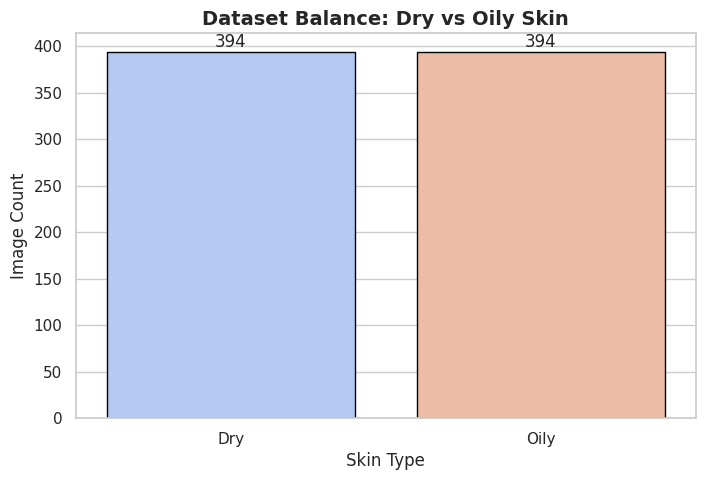

Total Images available for training: 788


In [ ]:
# Create summary of the dataset
stats = []
for cls in classes:
    path = os.path.join(train_dir, cls)
    count = len(os.listdir(path))
    stats.append({'Skin Type': cls.capitalize(), 'Image Count': count})

df_stats = pd.DataFrame(stats)

# Plotting
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Skin Type', y='Image Count', hue='Skin Type', data=df_stats, palette='coolwarm', edgecolor='black', legend=False)

# Add labels on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='center', xytext=(0, 7), textcoords='offset points')

plt.title('Dataset Balance: Dry vs Oily Skin', fontsize=14, fontweight='bold')
plt.show()

print(f"Total Images available for training: {df_stats['Image Count'].sum()}")

### Raw Image Sample Inspection

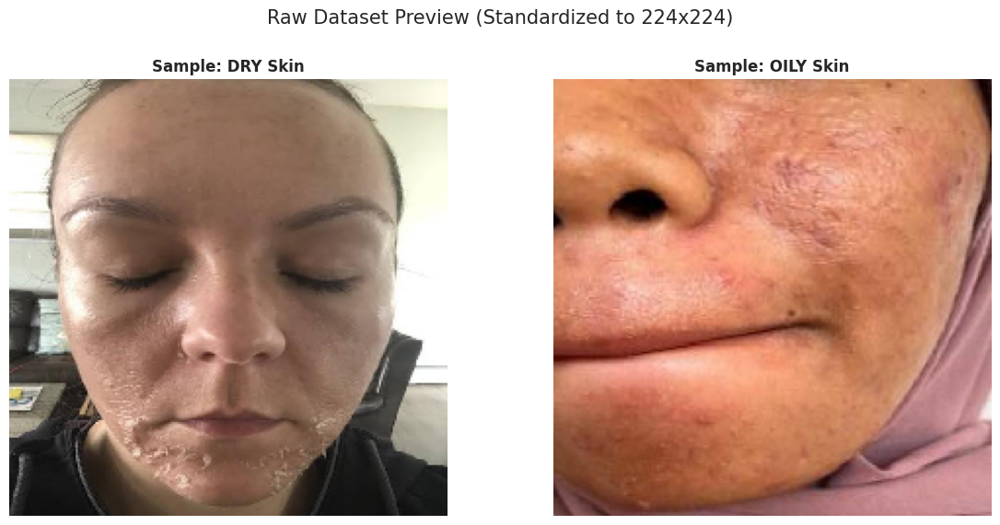

In [ ]:
# Visualizing raw samples from each class
plt.figure(figsize=(12, 6))

for i, cls in enumerate(classes):
    cls_path = os.path.join(train_dir, cls)
    # Get the first image file in the directory
    img_name = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][12]
    img = load_img(os.path.join(cls_path, img_name), target_size=(224, 224))

    plt.subplot(1, 2, i+1)
    plt.imshow(img)
    plt.title(f"Sample: {cls.upper()} Skin", fontsize=12, fontweight='bold')
    plt.axis('off')

plt.suptitle("Raw Dataset Preview (Standardized to 224x224)", fontsize=15)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Augmentation Strategy Visualization

Generating 8 augmented variations of a 'dry' skin image


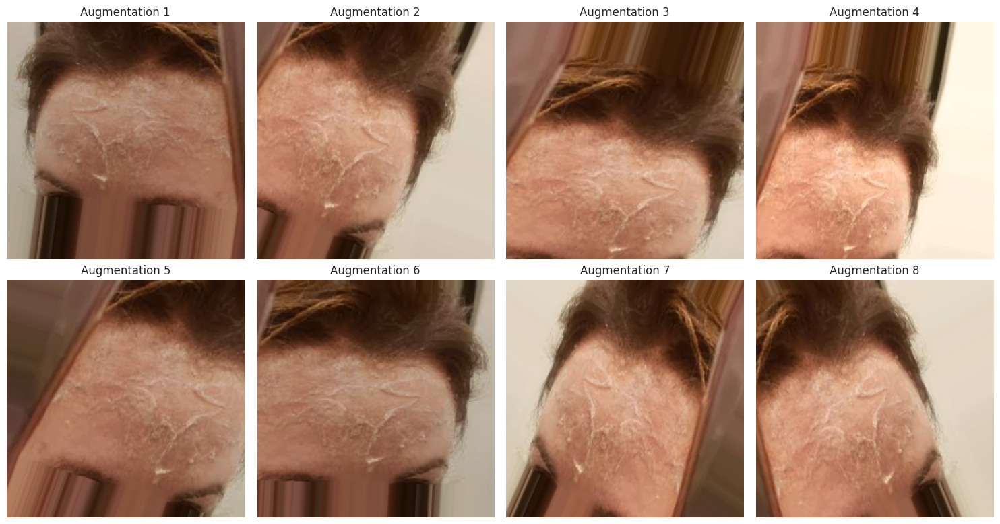

In [ ]:
# Data Augmentation
example_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    brightness_range=[0.8, 1.2],
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Pick one image to augment
sample_cls = classes[0]
sample_path = os.path.join(train_dir, sample_cls)
sample_img_name = os.listdir(sample_path)[26]
img = load_img(os.path.join(sample_path, sample_img_name), target_size=(224, 224))
x = img_to_array(img)
x = x.reshape((1,) + x.shape) # Reshape to (1, 224, 224, 3)

# Generate and plot augmented versions
print(f"Generating 8 augmented variations of a '{sample_cls}' skin image")
plt.figure(figsize=(15, 8))
i = 0
for batch in example_datagen.flow(x, batch_size=1):
    plt.subplot(2, 4, i + 1)
    plt.imshow(batch[0].astype('uint8'))
    plt.title(f"Augmentation {i+1}")
    plt.axis('off')
    i += 1
    if i == 8: break

plt.tight_layout()
plt.show()

# Defining Skin Type Classifier

In [ ]:
class SkinTypeClassifier:
    def __init__(self, input_shape=(224, 224, 3), num_classes=2):
        # Default input size for MobileNetV2 is 224x224 pixels with 3 color channels (RGB)
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model = None
        self.base_model = None
        self.history = None
        # Confidence threshold to identify 'Normal' skin if neither 'Dry' nor 'Oily' is dominant
        self.threshold_normal = 0.3

    def create_model_functional(self):
        """Builds the model using MobileNetV2 as a feature extractor"""
        # Load MobileNetV2 with pre-trained ImageNet weights
        # include_top=False removes the final classification layer to allow for custom output
        self.base_model = MobileNetV2(input_shape=self.input_shape, include_top=False, weights='imagenet')
        # Base model is initially frozen to preserve learned weights
        self.base_model.trainable = False

        # Define input layer
        inputs = tf.keras.Input(shape=self.input_shape)
        # Pass input through the pre-trained base model
        x = self.base_model(inputs, training=False)
        # Convert the 2D spatial features into a 1D vector for the final layers
        x = layers.GlobalAveragePooling2D()(x)

        # Custom Fully Connected (Dense) layers for specific skin classification task
        # Adding L2 Regularization and higher Dropout to solve overfitting
        x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
        x = layers.Dropout(0.5)(x)

        x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
        x = layers.Dropout(0.3)(x)

        # Final output layer with Softmax activation to provide class probabilities
        outputs = layers.Dense(self.num_classes, activation='softmax')(x)

        self.model = tf.keras.Model(inputs, outputs)
        return self.model

    def prepare_data_generators(self, train_dir, val_dir, batch_size=32):
        """Sets up image loading and augmentation"""
        train_datagen = ImageDataGenerator(
            preprocessing_function=preprocess_input, # MobileNetV2 specific scaling
            rotation_range=30,
            width_shift_range=0.2,
            height_shift_range=0.2,
            brightness_range=[0.8, 1.2],
            shear_range=0.15,
            zoom_range=0.2,
            horizontal_flip=True,
            fill_mode='nearest'
        )

        # Preprocessing validation data (not augmenting)
        val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

        # Load images from directory
        train_generator = train_datagen.flow_from_directory(
            train_dir,
            target_size=self.input_shape[:2],
            batch_size=batch_size,
            class_mode='categorical',
            classes=['dry', 'oily'],
            shuffle=True
        )

        val_generator = val_datagen.flow_from_directory(
            val_dir,
            target_size=self.input_shape[:2],
            batch_size=batch_size,
            class_mode='categorical',
            classes=['dry', 'oily'],
            shuffle=False
        )

        return train_generator, val_generator

    def train_model(self, train_generator, val_generator, epochs=50):
        """Executes a two-phase training strategy"""
        # 1. INITIAL TRAINING (Frozen Base)
        # Higher LR since base is frozen
        self.model.compile(optimizer=Adam(learning_rate=0.0005),
                           loss='categorical_crossentropy',
                           metrics=['accuracy'])

        # Callback to save only the best weights
        checkpoint = ModelCheckpoint('best_skin_model.keras', monitor='val_loss', save_best_only=True, mode='min')

        early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
        reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-7)

        print("--- Phase 1: Training Head Layers ---")
        history = self.model.fit(
            train_generator,
            epochs=epochs // 2,
            validation_data=val_generator,
            callbacks=[early_stop, reduce_lr, checkpoint]
        )

        # 2. FINE-TUNING (Unfreeze top layers)
        # To solve Transition Shock, we unfreeze fewer later layers and use a small Learning Rate
        print("\n--- Phase 2: Fine-Tuning ---")
        self.base_model.trainable = True

        # Only unfreeze from layer 130 onwards
        fine_tune_at = 130
        for layer in self.base_model.layers[:fine_tune_at]:
            layer.trainable = False

        # Recompiling with an extremely low learning rate to avoid destroying pre-trained weights
        self.model.compile(
            optimizer=Adam(learning_rate=1e-5),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        fine_tune_history = self.model.fit(
            train_generator,
            epochs=epochs,
            initial_epoch=history.epoch[-1],
            validation_data=val_generator,
            callbacks=[early_stop, reduce_lr, checkpoint]
        )

        # Merge the training logs from both phases for plotting
        for key in history.history.keys():
            history.history[key] += fine_tune_history.history[key]

        self.history = history
        return history

    def plot_training_history(self):
        """Visualizes the model's accuracy and loss over time"""
        if self.history is None: return

        acc = self.history.history['accuracy']
        val_acc = self.history.history['val_accuracy']
        loss = self.history.history['loss']
        val_loss = self.history.history['val_loss']

        plt.figure(figsize=(14, 5))
        # Plot Accuracy
        plt.subplot(1, 2, 1)
        plt.plot(acc, label='Training Accuracy')
        plt.plot(val_acc, label='Validation Accuracy')
        plt.axvline(x=len(acc)//2, color='r', linestyle='--', label='Fine-tuning Start')
        plt.title('Model Accuracy')
        plt.legend()

        # Plot Loss
        plt.subplot(1, 2, 2)
        plt.plot(loss, label='Training Loss')
        plt.plot(val_loss, label='Validation Loss')
        plt.axvline(x=len(loss)//2, color='r', linestyle='--', label='Fine-tuning Start')
        plt.title('Model Loss')
        plt.legend()
        plt.show()

    def predict_skin_type(self, image_path):
        """Processes an image and returns the predicted skin type"""
        # Load and resize image for the model
        img = tf.keras.preprocessing.image.load_img(image_path, target_size=self.input_shape[:2])
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        # Model expects a batch, so we expand dimensions
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)

        # Run inference
        preds = self.model.predict(img_array, verbose=0)[0]
        dry_conf, oily_conf = preds[0], preds[1]

        # If the model is not confident enough in 'Dry' or 'Oily', it defaults to 'Normal'
        if max(dry_conf, oily_conf) < (1 - self.threshold_normal):
            return "Normal", 1 - max(dry_conf, oily_conf)

        return ("Dry" if dry_conf > oily_conf else "Oily"), max(dry_conf, oily_conf)

    def save_model(self, filepath):
        """Exports the trained model to a file."""
        if self.model is not None:
            self.model.save(filepath)
        else:
            raise ValueError("Model has not been initialized or trained yet.")

# Execution Block

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 788 images belonging to 2 classes.
Found 146 images belonging to 2 classes.
--- Phase 1: Training Head Layers ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 310s 12s/step - accuracy: 0.5760 - loss: 3.9408 - val_accuracy: 0.6781 - val_loss: 3.4989 - learning_rate: 5.0000e-04
Epoch 2/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.6453 - loss: 3.4502 - val_accuracy: 0.7055 - val_loss: 3.1512 - learning_rate: 5.0000e-04
Epoch 3/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.6720 - loss: 3.1088 - val_accuracy: 0.7123 - val_loss: 2.8512 - learning_rate: 5.0000e-04
Epoch 4/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.6918 - loss: 2.7991 - val_accuracy: 0.7534 - val_loss: 2.5704 - learning_rate: 5.0000e-04
Epoch 5/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.6912 - loss: 2.5620 - val_accuracy: 0.7329 - val_loss: 2.3681 - learning_rate: 5.0000e-04
Epoch 6/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.6998 - loss: 2.3515 - val_accuracy: 0.7397 - val_loss: 2.1560 - learning_rate: 5.0000e-04
Epoch 7/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.7499 - los

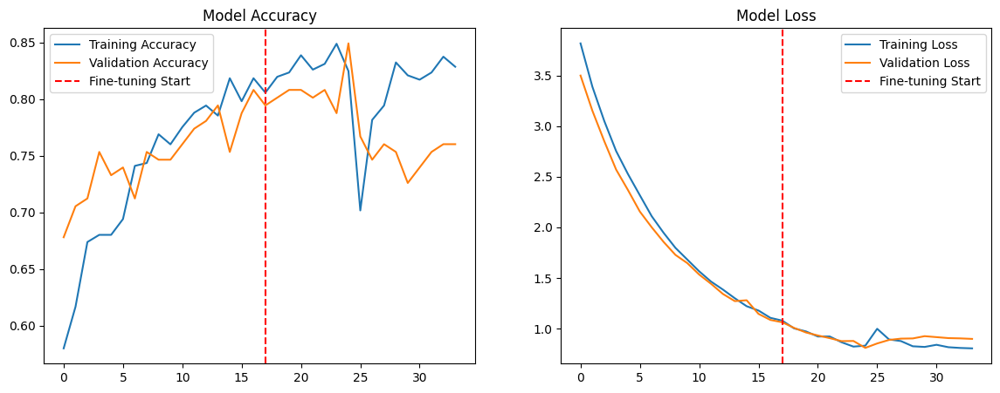

In [ ]:
if __name__ == "__main__":
    # Initialize the classifier
    classifier = SkinTypeClassifier()
    classifier.create_model_functional()

    # Check if directory exists before starting
    if os.path.exists(train_dir):
        # Prepare generators, train the model, and display results
        train_gen, val_gen = classifier.prepare_data_generators(train_dir, val_dir)
        classifier.train_model(train_gen, val_gen)
        classifier.plot_training_history()

# Save Model

In [ ]:
classifier.save_model("skin_type_classifier.h5")
print("\nModel saved successfully")


Model saved successfully


# Testing Skin Type

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 4.5 MB/s eta 0:00:00


# Loading Skin Type Classifier Model

In [ ]:
model_path = '/content/drive/MyDrive/skin_type_classifier.h5'
model = load_model(model_path)

In [ ]:
# Class labels used during training
class_labels = ['Dry', 'Oily']

# Standard dimensions expected by the model
img_height, img_width = 224, 224

# Image Preprocessing

In [ ]:
def preprocess_uploaded_image(img_path):
    """Converts a raw image file into a format compatible with the neural network"""
    # Load image and resize it to the required target size
    img = image.load_img(img_path, target_size=(img_height, img_width))
    # Convert image pixels to a 3D Numpy array (Height, Width, Channels)
    img_array = image.img_to_array(img)
    img_array = preprocess_input(img_array)
    # Expand dimensions to create a 'batch' of 1 (1, 224, 224, 3)
    return np.expand_dims(img_array, axis=0)

# Inference

Saving 20250323_131124.jpg to 20250323_131124.jpg


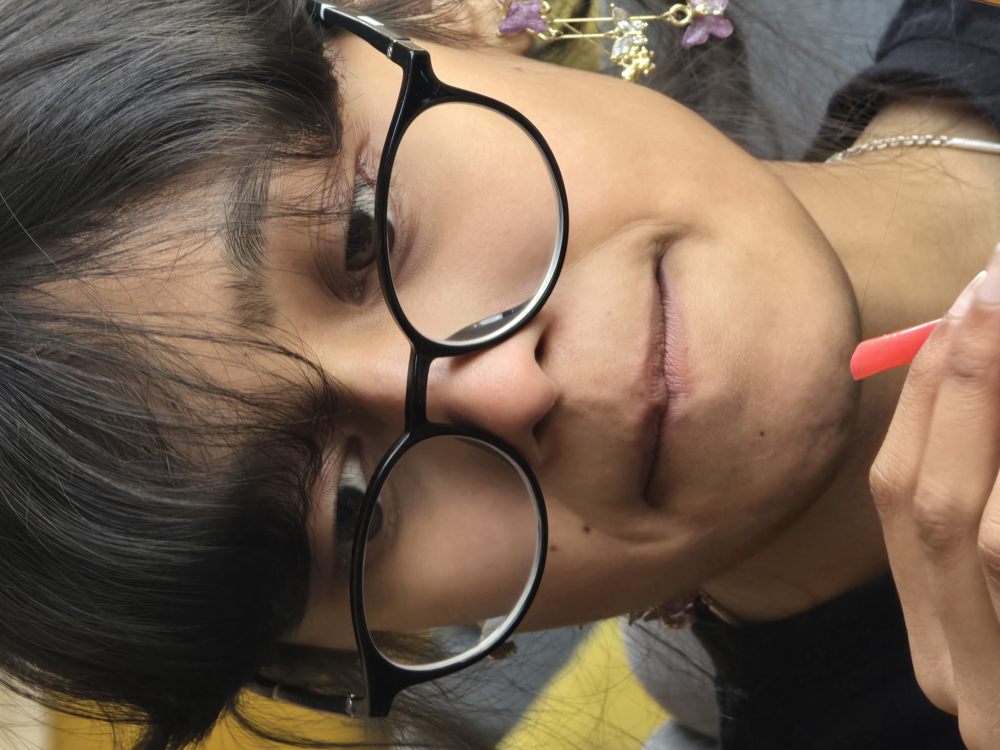

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Class probabilities:
Dry: 39.88%
Oily: 60.12%

Predicted Skin Type: Normal (60.12%)


In [ ]:
# Upload image(s)
uploaded = files.upload()

# Heuristic Logic for 'Normal' Skin
# If no class reaches 65% confidence, it's considered 'Normal'
threshold = 0.65  # Confidence threshold
# If the difference between Dry and Oily is less than 15%, it's 'Normal'
margin = 0.15

for filename in uploaded.keys():
    display(Image(filename))

    # Preprocess and predict
    img_array = preprocess_uploaded_image(filename)
    predictions = model.predict(img_array)[0]  # Returns a list of probabilities [dry_prob, oily_prob]

    # Print class probabilities
    print("Class probabilities:")
    for i, prob in enumerate(predictions):
        print(f"{class_labels[i]}: {prob * 100:.2f}%")

    # Extract confidences
    dry_conf = predictions[0]
    oily_conf = predictions[1]

    # Decide skin type
    if max(dry_conf, oily_conf) < threshold or abs(dry_conf - oily_conf) < margin:
        predicted_type = "Normal"
        confidence = max(dry_conf, oily_conf)
    else:
        predicted_type = class_labels[np.argmax(predictions)]
        confidence = max(dry_conf, oily_conf)

    # Display final result
    print(f"\nPredicted Skin Type: {predicted_type} ({confidence * 100:.2f}%)")

Saving download (1).jpg to download (1).jpg
Saving download.jpg to download.jpg
Saving download.png to download.png


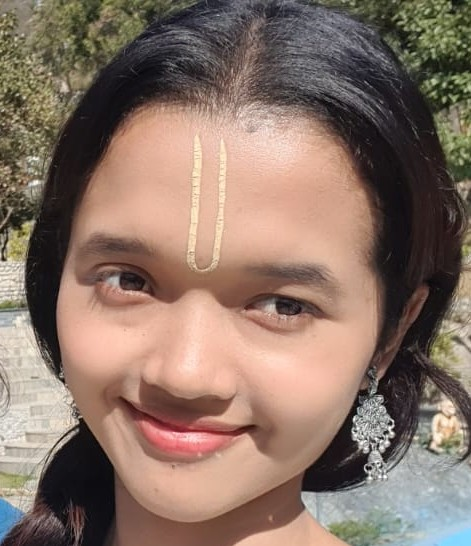

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Class probabilities:
Dry: 60.20%
Oily: 39.80%

Predicted Skin Type: Normal (60.20%)


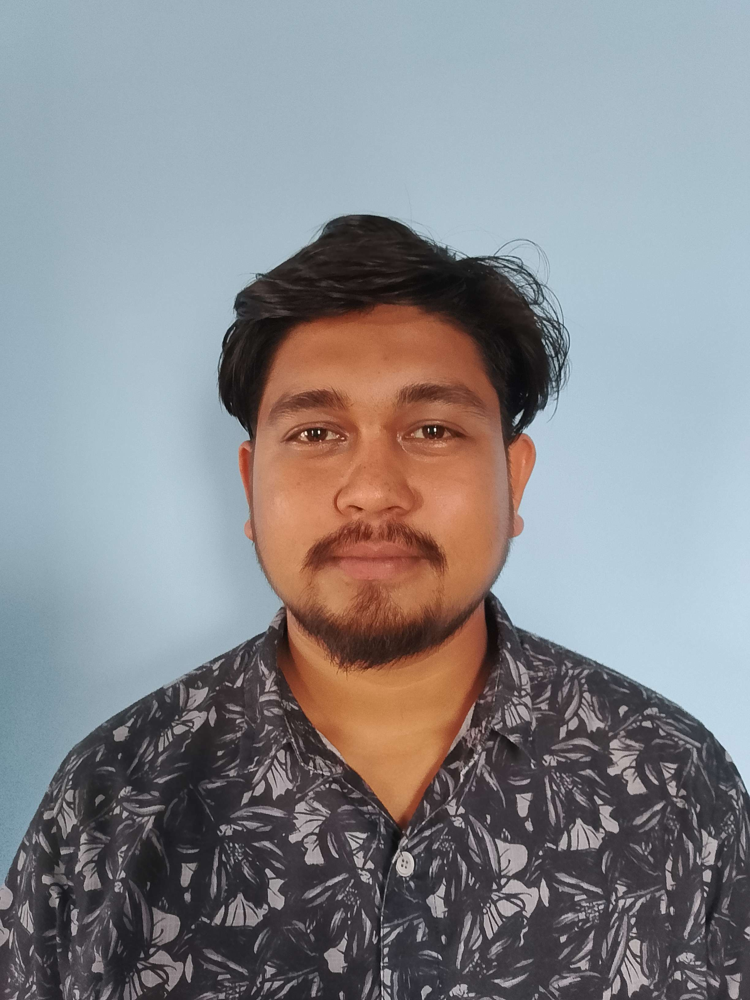

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Class probabilities:
Dry: 21.40%
Oily: 78.60%

Predicted Skin Type: Oily (78.60%)


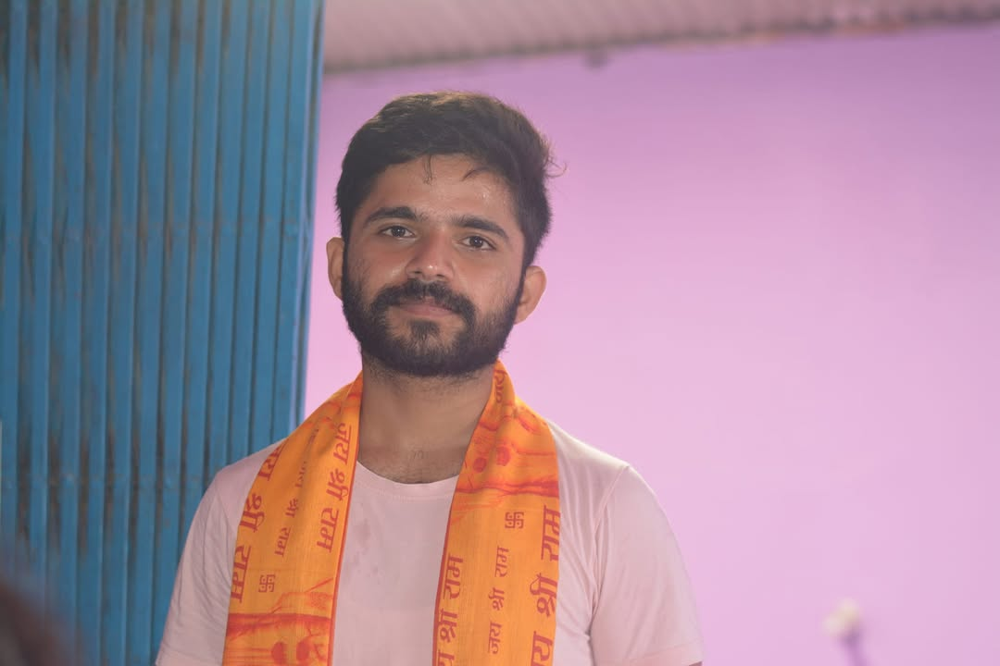

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Class probabilities:
Dry: 1.28%
Oily: 98.72%

Predicted Skin Type: Oily (98.72%)


In [ ]:
# Upload image(s)
uploaded = files.upload()

# Heuristic Logic for 'Normal' Skin
# If no class reaches 65% confidence, it's considered 'Normal'
threshold = 0.65  # Confidence threshold
# If the difference between Dry and Oily is less than 15%, it's 'Normal'
margin = 0.15

for filename in uploaded.keys():
    display(Image(filename))

    # Preprocess and predict
    img_array = preprocess_uploaded_image(filename)
    predictions = model.predict(img_array)[0]  # Returns a list of probabilities [dry_prob, oily_prob]

    # Print class probabilities
    print("Class probabilities:")
    for i, prob in enumerate(predictions):
        print(f"{class_labels[i]}: {prob * 100:.2f}%")

    # Extract confidences
    dry_conf = predictions[0]
    oily_conf = predictions[1]

    # Decide skin type
    if max(dry_conf, oily_conf) < threshold or abs(dry_conf - oily_conf) < margin:
        predicted_type = "Normal"
        confidence = max(dry_conf, oily_conf)
    else:
        predicted_type = class_labels[np.argmax(predictions)]
        confidence = max(dry_conf, oily_conf)

    # Display final result
    print(f"\nPredicted Skin Type: {predicted_type} ({confidence * 100:.2f}%)")

Saving 20250323_081404.jpg to 20250323_081404.jpg


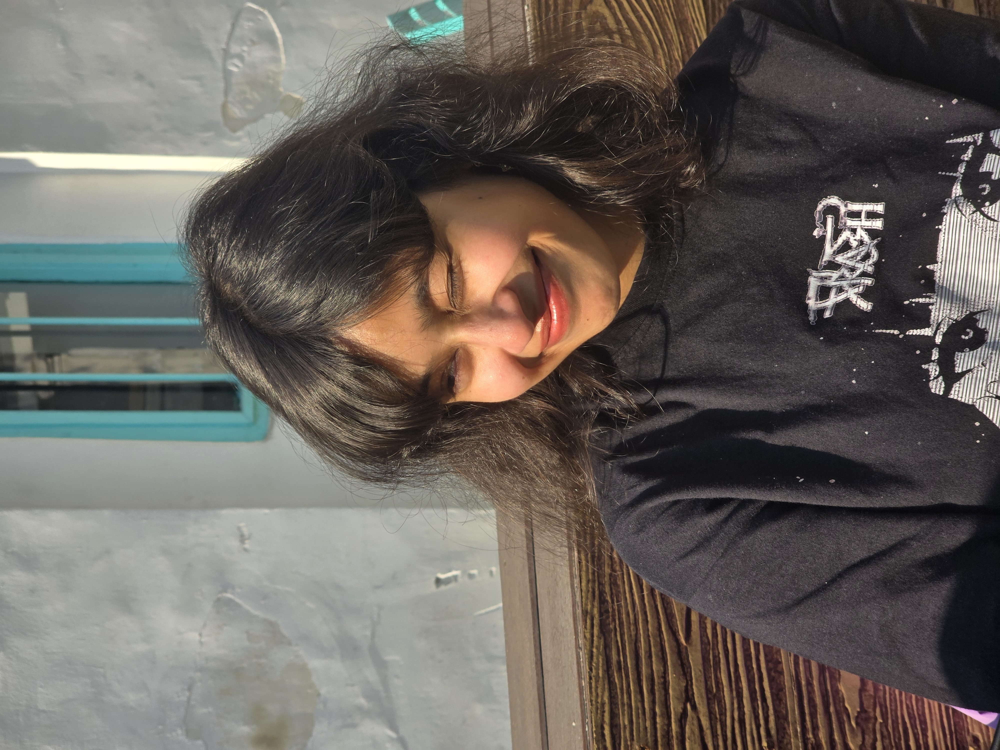

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Class probabilities:
Dry: 54.01%
Oily: 45.99%

Predicted Skin Type: Normal (54.01%)


In [ ]:
# Upload image(s)
uploaded = files.upload()

# Heuristic Logic for 'Normal' Skin
# If no class reaches 65% confidence, it's considered 'Normal'
threshold = 0.65  # Confidence threshold
# If the difference between Dry and Oily is less than 15%, it's 'Normal'
margin = 0.15

for filename in uploaded.keys():
    display(Image(filename))

    # Preprocess and predict
    img_array = preprocess_uploaded_image(filename)
    predictions = model.predict(img_array)[0]  # Returns a list of probabilities [dry_prob, oily_prob]

    # Print class probabilities
    print("Class probabilities:")
    for i, prob in enumerate(predictions):
        print(f"{class_labels[i]}: {prob * 100:.2f}%")

    # Extract confidences
    dry_conf = predictions[0]
    oily_conf = predictions[1]

    # Decide skin type
    if max(dry_conf, oily_conf) < threshold or abs(dry_conf - oily_conf) < margin:
        predicted_type = "Normal"
        confidence = max(dry_conf, oily_conf)
    else:
        predicted_type = class_labels[np.argmax(predictions)]
        confidence = max(dry_conf, oily_conf)

    # Display final result
    print(f"\nPredicted Skin Type: {predicted_type} ({confidence * 100:.2f}%)")

Saving download (2).jpg to download (2).jpg


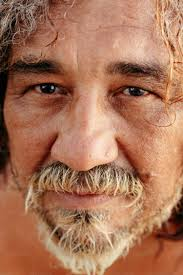

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Class probabilities:
Dry: 77.51%
Oily: 22.49%

Predicted Skin Type: Dry (77.51%)


In [ ]:
# Upload image(s)
uploaded = files.upload()

# Heuristic Logic for 'Normal' Skin
# If no class reaches 65% confidence, it's considered 'Normal'
threshold = 0.65  # Confidence threshold
# If the difference between Dry and Oily is less than 15%, it's 'Normal'
margin = 0.15

for filename in uploaded.keys():
    display(Image(filename))

    # Preprocess and predict
    img_array = preprocess_uploaded_image(filename)
    predictions = model.predict(img_array)[0]  # Returns a list of probabilities [dry_prob, oily_prob]

    # Print class probabilities
    print("Class probabilities:")
    for i, prob in enumerate(predictions):
        print(f"{class_labels[i]}: {prob * 100:.2f}%")

    # Extract confidences
    dry_conf = predictions[0]
    oily_conf = predictions[1]

    # Decide skin type
    if max(dry_conf, oily_conf) < threshold or abs(dry_conf - oily_conf) < margin:
        predicted_type = "Normal"
        confidence = max(dry_conf, oily_conf)
    else:
        predicted_type = class_labels[np.argmax(predictions)]
        confidence = max(dry_conf, oily_conf)

    # Display final result
    print(f"\nPredicted Skin Type: {predicted_type} ({confidence * 100:.2f}%)")